# Reverse stress testing: the most plausible scenario that breaks the bank

**Question:** How far from its baseline must real GDP growth and unemployment move, and held for three years, before Banco
Andino's CET1 falls to the Chilean legal minimum stack, and how plausible is that scenario?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 04 and 05 of this topic (the satellites and the capital plan)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state a reverse stress test formally, as the scenario of minimum Mahalanobis distance among those that reach a loss
  threshold, and say what its plausibility is;
- compute the failure point of the bank, the headroom of CET1 over the Chilean legal stack, as a loss in CLP millions;
- build the bank's net loss as a function of two macro factors from the engine's satellites and see its shape;
- solve the problem in closed form on the linearised loss and numerically on the true loss from four starts, and see why the
  two answers differ;
- check the solution with the engine, watch the check turn red on a planted failure, and put the answer in scale against the
  Federal Reserve scenario and the global financial crisis.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. 
The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Imports, versions and the readers; the pipeline folder goes on the path because the pipeline is never installed
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats
from riskvalidation.stress import capital, reverse, satellites
from riskvalidation.validation import stress as stress_tests

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c18 import satellites as c18_satellites


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the reverse-stress variant of **C18** (Banco Andino) and the pieces of the baseline that its loss is built from.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 1.0.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/reverse-stress.json` (the failure point, the factor space, the committed solution and its four starts), `baseline.json` (the baseline path, the capital at the jump-off, the baseline PPNR and expected losses, the exposure of each loan class, the back-cast rates), `models-banco-andino.json` (the satellite coefficients) and `fed-2026-severely-adverse.json` (the severity rows that compare the scenario with the global financial crisis).
- **Banco Andino's thresholds are conventions.** The failure point, CET1 at the legal minimum stack, is the case's formulation and **not regulatory text**; the CET1 share of Pillar 2 in that stack is a stated assumption (0.0625 percent of RWA).

In [2]:
# The reverse-stress document, the baseline pieces its loss is built from and the satellites' models
baseline = read_json("C18/baseline.json")["outputs"]
reverse_doc = read_json("C18/reverse-stress.json")
solution_doc = reverse_doc["outputs"]
models = read_json("C18/models-banco-andino.json")["fit"]
fed = read_json("C18/fed-2026-severely-adverse.json")["outputs"]
failure = solution_doc["failure_point"]
start = baseline["capital_start"]
print(solution_doc["kind"], solution_doc["loss_model"]["kind"], failure["label"], failure["horizon_years"])

reverse nonlinear contraste-formulation-not-regulatory 3


## Method

### Step 1: the question and its formal statement

A stress test starts from a scenario and asks what happens. A **reverse stress test** starts from an outcome and asks which scenarios cause it: the European guideline EBA/GL/2018/04 defines it as one that begins with a pre-defined outcome and explores the scenarios that might lead to it (dossier 01, J.4). The formal statement is Contraste's, not regulatory text. For a loss $L(x)$ as a function of the **deviation $x$ of the macro factors from their baseline**, with factor covariance $\Sigma$, the most plausible scenario that reaches a loss threshold $\ell$ is the one of **highest density** among those that do, which for Gaussian (and elliptical) factors is the one of **minimum Mahalanobis distance**:

$$x^{*} = \arg\min_x\; x^{\top}\Sigma^{-1}x \quad\text{subject to}\quad L(x) \ge \ell, \qquad d^{*} = \sqrt{x^{*\top}\Sigma^{-1}x^{*}}.$$

The attribution of this elliptical result to a specific paper is UNVERIFIED in the dossier (05, H.5); Glasserman, Kang and Kang (2015) estimate the most likely scenarios given large losses by empirical likelihood instead, which the engine does not implement. For a **linear loss** $L(x) = g^{\top}x$ the problem has a closed form,

$$x^{*} = \frac{\Sigma g\,\ell}{g^{\top}\Sigma g}, \qquad d^{*} = \frac{\ell}{\sqrt{g^{\top}\Sigma g}},$$

and otherwise it is solved numerically. The **plausibility** of a solution is $P(\chi^2_k \ge d^{*2})$ with $k$ the number of factors: how often a scenario at least that far from the baseline happens under the factor model.

The next cell recomputes the stack with the engine's `chilean_cet1_stack` and the loss threshold of the case, the headroom of
the jump-off CET1 over that stack in CLP millions, and draws the two ratios and the headroom between them.

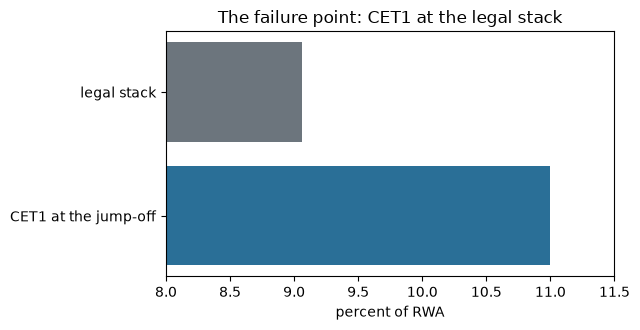

legal stack, percent of RWA 9.0625
CET1 ratio at the jump-off and RWA 0.11 7492853.0
loss threshold, CLP millions 145174.0


In [3]:
# The legal CET1 stack with the engine, and the loss threshold: the headroom of CET1 over the stack
parts = failure["stack"]
stack = capital.chilean_cet1_stack(parts["c_ccyb"], parts["c_dsib"], parts["p2_cet1"]["value"])
threshold = (start["cet1_ratio"] - stack) * start["rwa_clp_m"]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh(["CET1 at the jump-off", "legal stack"], [start["cet1_ratio"] * 100, stack * 100],
        color=["#2a6f97", "#6c757d"])
ax.set_xlim(8, 11.5)
ax.set_xlabel("percent of RWA")
ax.set_title("The failure point: CET1 at the legal stack")
fig.tight_layout()
plt.show()
print("legal stack, percent of RWA", round(stack * 100, 4))
print("CET1 ratio at the jump-off and RWA", start["cet1_ratio"], round(start["rwa_clp_m"], 1))
print("loss threshold, CLP millions", round(threshold, 1))

The jump-off CET1 ratio of 11.0 percent sits 1.9375 points above the legal stack of 9.0625 percent, the stack being 4.5
percent, 2.5 conservation, the countercyclical and systemic buffers and the CET1 share of Pillar 2, and on RWA of CLP
7,492,853 million that headroom is a loss of 145,174.0 million. A reverse stress test asks which scenario produces a net loss
of that size over three years, and the formal question is the one stated above. The axis of the figure is cut to start at 8
percent so the headroom can be seen, and the failure point is Contraste's formulation, not regulatory text.

### Step 2: the factors

The two factors are real GDP growth and the unemployment rate, the regressors of the satellites, and their joint behaviour is the sample covariance of 1985 to 2019, the fit window of the satellites. A scenario here is a **persistent deviation** of both factors from the Federal Reserve baseline path, the same deviation in every one of the twelve quarters. The engine validates the covariance before use (symmetric and positive definite) and refuses otherwise.

The next cell reads the committed covariance of the two factors, draws its ellipses of Mahalanobis distance 1, 2 and 3, and
shows `reverse_stress_linear` refusing a covariance that is not positive definite.

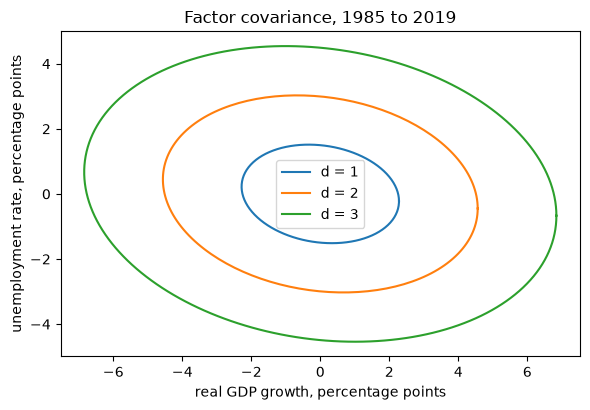

standard deviations [2.2809 1.5136] correlation -0.1474
a covariance that is not positive definite is refused


In [4]:
# The factor covariance, its Mahalanobis ellipses, and the refusal of a covariance that is not positive definite
space = solution_doc["factor_space"]
cov = np.array(space["covariance"])
sd = np.array([f["sd"] for f in space["factors"]])
angle = np.linspace(0, 2 * np.pi, 200)
root = np.linalg.cholesky(cov)
fig, ax = plt.subplots(figsize=(6, 4.2))
for radius in (1, 2, 3):
    ellipse = root @ np.vstack([np.cos(angle), np.sin(angle)]) * radius
    ax.plot(ellipse[0], ellipse[1], label=f"d = {radius}")
ax.set_xlabel("real GDP growth, percentage points")
ax.set_ylabel("unemployment rate, percentage points")
ax.set_title("Factor covariance, 1985 to 2019")
ax.legend()
fig.tight_layout()
plt.show()
print("standard deviations", np.round(sd, 4), "correlation", round(float(cov[0, 1] / (sd[0] * sd[1])), 4))
try:
    reverse.reverse_stress_linear(np.array([1.0, 1.0]), np.array([[1.0, 2.0], [2.0, 1.0]]), 1.0)
except ValueError:
    print("a covariance that is not positive definite is refused")

The ellipses are the sets of scenarios that are equally likely under the factor model: a point on the ring of distance 2 is
less likely than one at distance 1 and as likely as any other point of that ring. They are slightly tilted because growth and
unemployment move in opposite directions, with a correlation of minus 0.147, and wider along growth, whose standard deviation
is 2.28 points, than along unemployment, at 1.51. The engine refuses a covariance that is not symmetric and positive definite,
as the matrix printed last, because a Mahalanobis distance is meaningless without it.

### Step 3: the loss of the bank as a function of the factors

The loss of the reverse stress is the **three-year loss of the bank net of the cumulative baseline PPNR**: CET1 at the jump-off plus the cumulative PPNR less the cumulative losses reaches the legal stack exactly when this net loss equals the headroom of step 1. It is built from pieces the notebook has already used. For a deviation $x = (x_{\text{GDP}}, x_{\text{unemployment}})$:

1. shift the baseline regressor path of every quarter by $x$;
2. project the five satellites (notebook 04) from the last realised rates;
3. mix the loan types into the three classes with the case's weights and take, for each year, the exposure of each class times the mean of its four quarterly rates;
4. add the expected losses of market and operational risk for three years (3 times the annual figure) and subtract the cumulative PPNR of the baseline scenario.

This is the same wiring as the pipeline's own `loss_fn` (`data-pipeline/pipeline/cases/c18/bake.py`), with every statistic coming from the engine's `project_scenario`.

The next cell collects the baseline path, the last realised rates, the class exposures and the two constant pieces of the net
loss, and rebuilds the five satellites of notebook 04 from the committed coefficients. The class mix and the yearly credit
loss are the pipeline's own functions `class_rates` and `credit_losses`.

In [5]:
# The baseline path, the last rates, the class exposures and the two constant pieces of the net loss
NAMES = ("real_gdp_growth", "unemployment_rate")
base_paths = {p["maps_to_regressor"]: p for p in baseline["scenario"]["paths"]}
base_path = np.column_stack([[row["value"] for row in base_paths[name]["transposed"]] for name in NAMES])
jump_off = np.array([[base_paths[name]["transposition"]["target"]["value"] for name in NAMES]])
last_rate = {b["fed_loan_type"]: b["quarters"][-1]["realised"] for b in baseline["backcast"]["per_loan_type"]}
exposure = {k["banco_andino_class"]: k["exposure_clp_m"] for k in baseline["satellites"]["banco_andino_classes"]}
marginals = baseline["aggregation"]["marginals"]
other_expected = sum(m["el_clp_m"] for m in marginals if m["risk"] in ("market", "operational"))
baseline_ppnr = sum(row["ppnr_clp_m"] for row in baseline["headline_cet1"]["ppnr"]["rows"])


def satellite_fit(model):
    names = list(dict.fromkeys(r["name"] for r in model["regressors"]))
    coefficients = model["coefficients"]
    return satellites.SatelliteFit(
        link=model["link"], window_start=model["sample_window"]["start"], window_end=model["sample_window"]["end"],
        n_obs=model["n_obs"], ar_order=model["ar_order"], regressor_names=tuple(names),
        lags=tuple(sorted({r["lag"] for r in model["regressors"]})),
        coefficient_names=tuple(c["name"] for c in coefficients),
        estimates=tuple(c["estimate"] for c in coefficients),
        std_errors=tuple(c["std_error"] for c in coefficients), r_squared=model["fit_statistics"]["r_squared"],
        residual_sd=model["fit_statistics"]["residual_sd"])


fits = {m["fed_loan_type"]: satellite_fit(m) for m in models["satellites"]}
last_link = {t: satellites.link(f.link, np.array([last_rate[t]])) for t, f in fits.items()}

The next cell defines the net loss of a deviation $x$ of the two factors, the callback that the engine's solver takes: it
shifts the baseline path by $x$, projects the five satellites with `project_scenario`, and lets the pipeline's functions mix
them into classes and total three years of credit loss. It draws the net loss along each factor axis against the threshold.

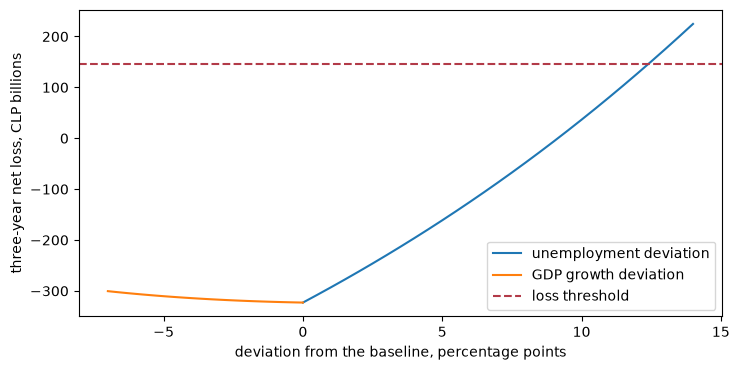

other expected losses per year 1187.54
baseline PPNR over three years 441263.1
net loss at the baseline -322940.3
x = [-1.0, 0.0]: net loss   -321,627.4
x = [0.0, 3.0]: net loss   -229,840.7
x = [-2.0, 6.0]: net loss   -124,811.9
x = [-2.58, 12.42]: net loss    145,240.8


In [6]:
# The net loss as a function of the two factor deviations, and its shape along each axis
def net_loss(x):
    path = base_path + np.asarray(x, dtype=float)
    projections = {t: satellites.project_scenario(f, last_link[t], jump_off, path) for t, f in fits.items()}
    credit = sum(c18_satellites.credit_losses(c18_satellites.class_rates(projections), exposure))
    return float(credit) + 3.0 * other_expected - baseline_ppnr


steps = np.linspace(0, 14, 29)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(steps, [net_loss([0.0, u]) / 1e3 for u in steps], label="unemployment deviation")
ax.plot(-steps / 2, [net_loss([-g, 0.0]) / 1e3 for g in steps / 2], label="GDP growth deviation")
ax.axhline(threshold / 1e3, color="#b23a48", linestyle="--", label="loss threshold")
ax.set_xlabel("deviation from the baseline, percentage points")
ax.set_ylabel("three-year net loss, CLP billions")
ax.legend()
fig.tight_layout()
plt.show()
print("other expected losses per year", round(other_expected, 2))
print("baseline PPNR over three years", round(baseline_ppnr, 1))
print("net loss at the baseline", round(net_loss([0.0, 0.0]), 1))
for x in ([-1.0, 0.0], [0.0, 3.0], [-2.0, 6.0], [-2.58, 12.42]):
    print(f"x = {x}: net loss {net_loss(x):12,.1f}")

At the baseline the net loss is minus 322,940 million, because the baseline PPNR over three years, 441,263 million, exceeds
the losses, so the bank is 468,114 million of net loss away from the failure point and no stress at all is not the question
here. The unemployment curve bends upward and crosses the threshold at about 12.4 points, while the growth curve, over a range
of 7 points, is almost flat: a point of growth moves the loss by 1,055 million and a point of unemployment by 29,244. The
satellites make unemployment the dominant factor, and the solution will therefore be a large unemployment deviation and a
small growth one.

### Step 4: the closed form on the linearised loss

The loss is not linear, because of the probit link, but at the baseline it has a **gradient** $g = \nabla L(0)$ in CLP millions per percentage point of each factor, which central finite differences give. The linear approximation is $L(x) \approx L(0) + g^{\top}x$, so the loss reaches the threshold $\ell$ when $g^{\top}x = \ell - L(0)$, and `reverse_stress_linear(g, cov, ell - L(0))` returns the closed-form scenario. The sign of the gradient tells the economics: negative on GDP growth (less growth, more loss) and positive on unemployment.

The next cell computes the gradient by central differences, calls `reverse_stress_linear` with the loss to cover, and draws
the true net loss and its linearisation along the direction of the closed-form solution, against the threshold.

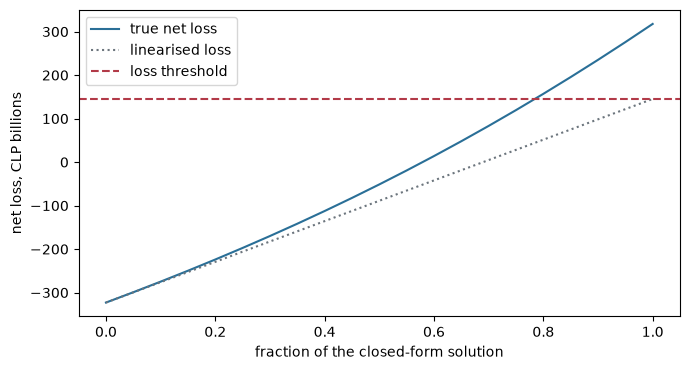

gradient, CLP millions per point (GDP growth, unemployment) [-1055. 29244.]
linear x*, distance [-4.776 15.835] 10.4767
true loss at the linear x*, CLP millions 317698.6
true loss over the threshold 2.2
plausibility of the linear scenario 1.46e-24


In [7]:
# Gradient of the net loss at the baseline, the closed-form solution of the linear problem and its true loss
h = 1e-4
gradient = np.array([(net_loss(np.eye(2)[k] * h) - net_loss(-np.eye(2)[k] * h)) / (2 * h) for k in range(2)])
loss_at_zero = net_loss([0.0, 0.0])
linear = reverse.reverse_stress_linear(gradient, cov, threshold - loss_at_zero)
scale = np.linspace(0, 1, 21)
true_curve = [net_loss(linear.x_star * s) / 1e3 for s in scale]
linear_curve = [(loss_at_zero + float(gradient @ linear.x_star) * s) / 1e3 for s in scale]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(scale, true_curve, color="#2a6f97", label="true net loss")
ax.plot(scale, linear_curve, color="#6c757d", linestyle=":", label="linearised loss")
ax.axhline(threshold / 1e3, color="#b23a48", linestyle="--", label="loss threshold")
ax.set_xlabel("fraction of the closed-form solution")
ax.set_ylabel("net loss, CLP billions")
ax.legend()
fig.tight_layout()
plt.show()
print("gradient, CLP millions per point (GDP growth, unemployment)", np.round(gradient, 0))
print("linear x*, distance", np.round(linear.x_star, 3), round(linear.distance, 4))
true_loss = net_loss(linear.x_star)
print("true loss at the linear x*, CLP millions", round(true_loss, 1))
print("true loss over the threshold", round(true_loss / threshold, 1))
print("plausibility of the linear scenario", f"{reverse.plausibility(linear.distance, 2):.2e}")

The linearisation is a straight line from the baseline, and the true loss is a convex curve above it, because the probit link
turns equal macro increments into growing loss rates. At the closed-form scenario, minus 4.78 points of growth and plus 15.84
of unemployment at a distance of 10.48, the linear loss just reaches the threshold, but the true loss there is CLP 317,699
million, 2.2 times as much. The closed form overshoots, and the true scenario that merely reaches the threshold is closer
to the baseline. That is the reason for the nonlinear solve of the next step.

### Step 5: the nonlinear problem, from several starts

The true problem is nonlinear, so the engine's `reverse_stress(loss_fn, cov, threshold, starts)` minimises $x^{\top}\Sigma^{-1}x$ subject to $L(x) \ge \ell$ with SLSQP from each start (central-difference gradients and warm restarts). A **local search proves nothing from one start**, so at least three starts are required and the best converged solution is returned with the result of every start. A start converges when SLSQP succeeds and the loss is within a relative tolerance of the threshold. The case's four starts are deterministic points in the adverse quadrant (growth falls, unemployment rises), in multiples of the factor standard deviations: $(-1, 5)$, $(-0.5, 7)$, $(-2, 8)$ and $(0, 9)$.

The next cell runs `reverse_stress` from the four starts of the case, prints each start with the committed row beside it,
and draws the Mahalanobis ellipses with the contour where the true net loss equals the threshold, the baseline, the
closed-form solution and the nonlinear one.

In [8]:
# Solve the nonlinear problem from the case's four starts and print each start beside the committed one
starts = [np.array([a * sd[0], b * sd[1]]) for a, b in ((-1.0, 5.0), (-0.5, 7.0), (-2.0, 8.0), (0.0, 9.0))]
best, each = reverse.reverse_stress(net_loss, cov, threshold, starts)
committed = solution_doc["solution"]
for k, (mine, theirs) in enumerate(zip(each, solution_doc["starts"]), start=1):
    print(f"start {k}: converged {mine.converged!s:5s} distance {mine.distance:.9f}")
    print(f"   committed: {theirs['converged']!s:5s} {theirs['distance']:.9f}")
print("x* =", np.round(best.x_star, 4), "z* =", np.round(best.z_star, 4), "distance", round(best.distance, 6))
print("loss at x*, threshold", round(best.loss_at_x, 3), round(threshold, 3))
print("plausibility P(chi2_2 >= d^2)", f"{reverse.plausibility(best.distance, 2):.2e}")
print("committed", f"{committed['plausibility']['tail_probability']:.2e}")

start 1: converged True  distance 8.205018940
   committed: True  8.205018940
start 2: converged False distance 8.205018940
   committed: False 8.205018940
start 3: converged True  distance 8.205018940
   committed: True  8.205018940
start 4: converged True  distance 8.205018940
   committed: True  8.205018940
x* = [-2.5805 12.4186] z* = [-1.1313  8.2046] distance 8.205019
loss at x*, threshold 145174.027 145174.027
plausibility P(chi2_2 >= d^2) 2.41e-15
committed 2.41e-15


The next cell evaluates the net loss on a grid of the factor plane, which takes a few seconds, and draws the contour where it
equals the threshold over the Mahalanobis ellipses.

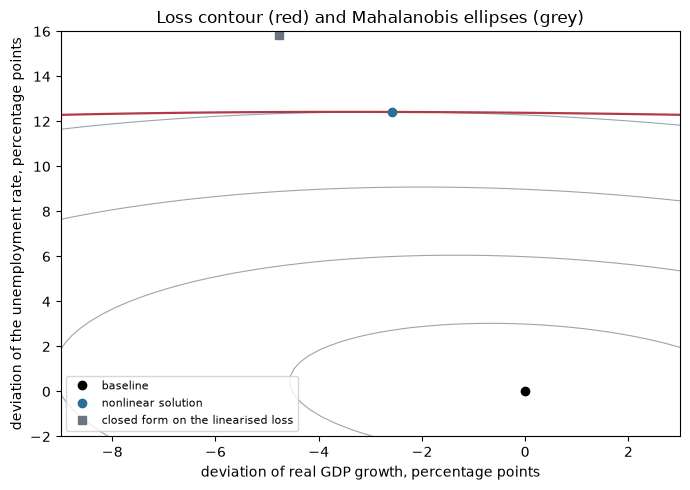

In [9]:
# The Mahalanobis ellipses, the contour where the net loss equals the threshold, and the two solutions
gx, gy = np.linspace(-9, 3, 61), np.linspace(-2, 16, 61)
grid_loss = np.array([[net_loss([a, b]) for a in gx] for b in gy])
p = np.linalg.inv(cov)
xx, yy = np.meshgrid(gx, gy)
distance_grid = np.sqrt(p[0, 0] * xx ** 2 + 2 * p[0, 1] * xx * yy + p[1, 1] * yy ** 2)
fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(gx, gy, distance_grid, levels=[2, 4, 6, round(best.distance, 3)], colors="#9aa5b1", linewidths=0.8)
ax.contour(gx, gy, grid_loss, levels=[threshold], colors="#b23a48", linewidths=1.6)
ax.plot([0], [0], "ko", label="baseline")
ax.plot(*best.x_star, "o", color="#2a6f97", label="nonlinear solution")
ax.plot(*linear.x_star, "s", color="#6c757d", label="closed form on the linearised loss")
ax.set_xlabel("deviation of real GDP growth, percentage points")
ax.set_ylabel("deviation of the unemployment rate, percentage points")
ax.set_title("Loss contour (red) and Mahalanobis ellipses (grey)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

The red contour is where the true net loss equals the threshold, and the solution is the point of it closest to the
baseline in Mahalanobis distance, where the contour is tangent to the last grey ellipse, of distance 8.2. It sits at minus
2.58 points of growth and plus 12.42 of unemployment, in standard deviations minus 1.13 and plus 8.20, and the closed-form
square beyond it is farther away, as the previous figure explained. Three of the four starts converged and the fourth stopped
at the same distance to twelve digits, which is what a local search must show before its answer is believed: the printed
distances agree with the committed ones, and the plausibility, 2.41e-15, is how rare such a scenario is under the factor model.

### Step 6: checking the solution

A numerical optimiser can stop at a point that is not a solution, so the engine ships a check, `reverse_solution_check(loss_at_x, threshold, distance, start_distances)`: **red** when the loss at the solution misses the threshold by more than a tolerance, or when any start found a point closer than the solution; **green** otherwise; `not_evaluated` with fewer than three starts. Its metric is the closest start over the solution's distance, less 1 (zero or positive when no start is closer).

The next cell runs the engine's `reverse_solution_check` on the solution and the distances of the converged starts, on a
planted failure, and on only two starts.

In [10]:
# Run the engine's solution check on the real solution, on a planted failure and on two starts only
converged = [s.distance for s in each if s.converged]
LIGHT = {"green": "green", "red": "red", "not_evaluated": "not evaluated"}
planted = converged[:-1] + [0.9 * best.distance]
cases = (("the solution", converged), ("a start at 90 percent of the distance", planted),
         ("two starts only", converged[:2]))
for label, distances in cases:
    check = stress_tests.reverse_solution_check(best.loss_at_x, threshold, best.distance, distances)
    print(f"{label:48s} {LIGHT[check.light.value]:14s} {len(distances)}")

the solution                                     green          3
a start at 90 percent of the distance            red            3
two starts only                                  not evaluated  2


### Step 7: how severe is the scenario that breaks the bank?

The solution is a deviation of both factors, **held for twelve quarters**, from the baseline. Two reference points give it scale. The Federal Reserve's severely adverse scenario peaks 5.5 points above its starting unemployment, which the committed severity row of the case compares with the 5.1 points of the global financial crisis (2008 Q1 to 2009 Q4).

The next cell reads the severity rows, expresses the solution in standard deviations of each factor, and draws the
unemployment deviation of the solution next to the Federal Reserve peak and that of the global financial crisis.

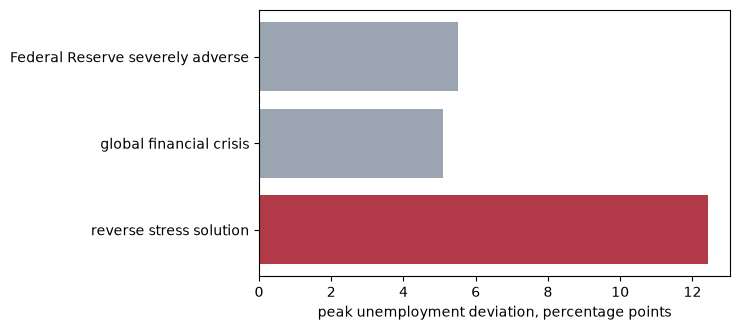

solution, GDP growth and unemployment, points -2.58 12.42
peaks, Federal Reserve and crisis 5.5 5.1000000000000005
in standard deviations [-1.13  8.2 ]
multiples of the Federal Reserve and crisis peaks
[2.3 2.4]
tail probability 2.41e-15
equivalent normal standard deviations 7.83


In [11]:
# Compare the solution with the Federal Reserve scenario and the global financial crisis on the unemployment factor
severity = {row["maps_to_regressor"]: row for row in fed["severity"]["rows"]}
unemployment = severity["unemployment_rate"]
x_gdp, x_unemployment = best.x_star
labels = ["Federal Reserve severely adverse", "global financial crisis",
          "reverse stress solution"]
values = [unemployment["path_peak_deviation"], unemployment["history_peak_deviation"], x_unemployment]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(labels[::-1], values[::-1], color=["#b23a48", "#9aa5b1", "#9aa5b1"])
ax.set_xlabel("peak unemployment deviation, percentage points")
fig.tight_layout()
plt.show()
print("solution, GDP growth and unemployment, points", round(x_gdp, 2), round(x_unemployment, 2))
print("peaks, Federal Reserve and crisis", values[0], values[1])
print("in standard deviations", np.round(best.z_star, 2))
print("multiples of the Federal Reserve and crisis peaks")
print(np.round(x_unemployment / np.array(values[:2]), 1))
tail = reverse.plausibility(best.distance, 2)
print("tail probability", f"{tail:.2e}")
print("equivalent normal standard deviations", round(float(stats.norm.isf(tail)), 2))

The unemployment deviation that breaks the bank, 12.42 points held for twelve quarters, is 2.3 times the Federal Reserve's
severely adverse peak of 5.5 and 2.4 times the 5.1 points of the global financial crisis. In standard deviations of the factor
model it is 8.2, equivalent to a single normal variable at 7.83 standard deviations. The bar chart puts the answer in a
scale the reader already has: the bank in this synthetic case does not fail in any scenario of the historical record. That says
more about the loss model than about the economy, since the loss is a floor and the PPNR carries two assumed ratios.

## Results

The two figures above carry the result: the factor plane with the loss contour and the solution, and the bar chart that puts
its unemployment deviation next to the two reference points. The numbers that answer the question are the ones printed under
them.

**Answer:** the most plausible scenario that takes Banco Andino to the legal stack is a persistent deviation of minus 2.58
points of real GDP growth and plus 12.42 points of unemployment, held for twelve quarters, at a Mahalanobis distance of
8.205019, a loss threshold of CLP 145,174.0 million and a plausibility of 2.4e-15, 7.83 standard deviations of a single normal
variable. The unemployment deviation is 2.3 times the Federal Reserve's severely adverse peak of 5.5 points and 2.4 times the
5.1 of the global financial crisis. The closed form on the linearised loss would have said minus 4.78 and plus 15.84 at a
distance of 10.48, 2.2 times too much loss at the solution, because the probit link is convex; and the solution check is
green with three converged starts, red when a start at 90 percent of the distance is planted.

What this notebook does not show: the loss is a floor (market and operational risk carry only their expected loss) and its PPNR
is a labelled row on assumed ratios, so the distance is a property of this model and its inputs; the satellites it runs on fail
their own back-cast (notebook 07), which is a reason to read the distance as a statement about the satellites; and the
empirical-likelihood estimator of Glasserman, Kang and Kang is not in the engine.

## Summary

- A reverse stress test starts from the failure and asks for the most plausible scenario that reaches it; the case's formal statement is the minimum Mahalanobis distance scenario on the loss surface, Contraste's formulation and not regulatory text.
- The failure point is CET1 at the Chilean legal minimum stack at the end of the three years; the threshold is the headroom of CET1 over it, and the loss is the three-year loss net of the baseline PPNR.
- For a linear loss the solution is closed form; the case's loss is nonlinear through the probit link, so the engine solves it numerically from several starts and a check refuses a solution that misses the threshold or has a closer start.
- The scenario that breaks the bank is far beyond any stress in the record: it needs a persistent shift of unemployment more than twice the Federal Reserve's severely adverse peak and a plausibility around $10^{-15}$ under the factor model, which says more about the bank's resilience in this synthetic case, and about what its inputs omit, than about the economy.

**What to try next.** Change the CET1 share of Pillar 2 in the stack of step 1 and watch the threshold and the distance move; then continue with notebook 07, which validates the aggregation and stress components with the engine's test batteries.

## References

- Glasserman, P., Kang, C. and Kang, W. (2015), Stress scenario selection by empirical likelihood, Quantitative Finance 15(1). https://doi.org/10.1080/14697688.2014.926019
- Dossiers 01 (J.4, the reverse stress formulation and EBA/GL/2018/04) and 05 (H.5, reverse stress testing) of the persisted Contraste research, as summarised in the SDD's research basis.
- This repository: `docs/contracts/engine/stress-api.md` (the reverse-stress functions) and `docs/design/features/c18/requirements.md` (CT-1815 and CT-1822).